I want to try 2 types of models:
- based on time/weather data
- based on time/location data

Time/weather model by User Type (Member/Casual Rider):
1) feature engineering
    - fetch holiday/weather data
    - compute time features
    - plot features 
    - make a prior analysis of features behaviour
    - corr matrix
    - choose what features put into model
    
2) Linear Regression
    - fit the OLS
    - check the summary
    - interpret the coefficients
    - plot residuals
    - analyse assuptions' violation
3) Poisson Regression
    - fit the OLS
    - check the summary
    - interpret the coefficients
    - plot residuals
    - analyse assuptions' violation
4) Negative Binomial Regression
    - fit the OLS
    - check the summary
    - interpret the coefficients
    - plot residuals
    - analyse assuptions' violation


In [ ]:
# data wrangling
import pandas as pd 
import numpy as np 
from pathlib import Path
import parquet

# data visualization
import seaborn as sns 
import matplotlib.pyplot as plt 

# features
import holidays 

# data modeling
import statsmodels.api as sm
import statsmodels.formula.api as smf


In [143]:
DATA_DIR = Path('data')


trips = pd.read_parquet(DATA_DIR / 'trips', columns=['trip_id', 'start_station_id', 'year', 'start_time', 'user_type'])
trips['year'] = trips['year'].astype(int)  

stations = pd.read_parquet(DATA_DIR / 'stations')[['station_id', 'name', 'neighbourhood', 'ward']]

df = trips.merge(
    stations.rename(columns={
        'station_id': 'start_station_id', 'name': 'start_station_name',
        'neighbourhood': 'start_neighbourhood', 'ward': 'start_ward',
    }),
    on='start_station_id', how='left',
)



In [ ]:
# trips.user_type.unique()

['Member', 'Casual']
Categories (2, str): ['Casual', 'Member']

In [147]:
# trips[trips.user_type.isna()]

## Time/weather model by User Type (Member/Casual Rider):


### 1. feature engineering

#### weather features

In [ ]:
# get weather data
weather = pd.read_parquet(DATA_DIR / 'weather', columns=['date_hour', 'temp_c', 'precip_mm', 'snowfall_cm', 'wind_kph'])
weather.head()

,date_hour,temp_c,precip_mm,snowfall_cm,wind_kph
0,2016-01-01 00:00:00,-0.0,0.0,0.0,18.9
1,2016-01-01 01:00:00,0.0,0.0,0.0,18.6
2,2016-01-01 02:00:00,0.0,0.0,0.0,20.0
3,2016-01-01 03:00:00,-0.0,0.0,0.0,20.8
4,2016-01-01 04:00:00,-0.1,0.0,0.0,21.3


In [153]:
trips_h = df.copy()
trips_h['date_hour'] = trips_h['start_time'].dt.floor('h')
trips_h['year_month'] = trips_h['start_time'].dt.to_period('M')

In [154]:
trips_h.head()

,trip_id,start_station_id,year,start_time,user_type,start_station_name,start_neighbourhood,start_ward,date_hour,year_month
0,53279,7100,2016,2016-07-09 01:03:00,Member,Dundas St E / Regent Park Blvd,Regent Park,Toronto Centre,2016-07-09 01:00:00,2016-07
1,53394,7097,2016,2016-07-09 02:15:00,Member,Riverdale Park North (Broadview Ave),North Riverdale,Toronto-Danforth,2016-07-09 02:00:00,2016-07
2,58314,7100,2016,2016-07-10 17:04:00,Member,Dundas St E / Regent Park Blvd,Regent Park,Toronto Centre,2016-07-10 17:00:00,2016-07
3,60784,7033,2016,2016-07-11 01:45:00,Member,Union Station,St Lawrence-East Bayfront-The Islands,Spadina-Fort York,2016-07-11 01:00:00,2016-07
4,93164,7059,2016,2016-07-18 13:35:00,Member,Front St W / Blue Jays Way,Harbourfront-CityPlace,Spadina-Fort York,2016-07-18 13:00:00,2016-07


In [155]:
monthly_active_stations = (trips_h
                            .groupby('year_month')['start_station_id']
                            .nunique()
                            .reset_index(name='active_stations')
                            .rename(columns = {'start_time':'year_month'})
                            )

In the previous section (EDA) we see very clearly that we have 2 distinct behaviours in the data for Members and Casual Riders. 
Probably I should separate them into 2 regression branches (control on user type?stratification? is it the same definition? ), but let's start from adding it as a category grouping variable:

In [ ]:
# aggregate by user type
hourly_trips = (trips_h
                   .groupby(['date_hour', 'user_type'])
                   .size()
                   .reset_index(name='trips')
                   )
hourly_trips['year_month'] = hourly_trips['date_hour'].dt.to_period('M')
hourly_trips = hourly_trips.merge(monthly_active_stations, on='year_month', how='left') 

In [162]:
hourly_trips.head()

,date_hour,user_type,trips,year_month,active_stations
0,2016-07-01 00:00:00,Casual,35,2016-07,200
1,2016-07-01 00:00:00,Member,90,2016-07,200
2,2016-07-01 01:00:00,Casual,34,2016-07,200
3,2016-07-01 01:00:00,Member,60,2016-07,200
4,2016-07-01 02:00:00,Casual,39,2016-07,200


#### holiday features

In [234]:
# get weather data
def build_holiday_calendar(years):
    """Ontario statutory holidays for the given years as a {date: name} dict,
    for flagging is_holiday on the trips panel."""
    return dict(holidays.Canada(subdiv="ON", years=years))

cal = build_holiday_calendar(range(2016, 2027))


#### time features

In [163]:
hourly_trips['date'] = hourly_trips['date_hour'].dt.date
hourly_trips['is_holiday'] = hourly_trips['date'].isin(cal)
hourly_trips['dow'] = hourly_trips['date_hour'].dt.day_of_week
hourly_trips['month'] = hourly_trips['date_hour'].dt.month
hourly_trips['hour'] = hourly_trips['date_hour'].dt.hour
hourly_trips['is_weekend'] = hourly_trips['dow'].isin([5, 6])
hourly_trips['workday'] = ~hourly_trips['is_weekend'] & ~hourly_trips['is_holiday']

#### create model matrix

In [ ]:
panel = (hourly_trips
         .merge(weather, on='date_hour', how='left')
         .dropna(subset=['temp_c', 'active_stations', 'user_type'])
         )
panel['trips_per_station'] = panel['trips'] / panel['active_stations']

In [166]:
panel.head()

,date_hour,user_type,trips,year_month,active_stations,date,is_holiday,dow,month,hour,is_weekend,workday,temp_c,precip_mm,snowfall_cm,wind_kph,trips_per_station
0,2016-07-01 00:00:00,Casual,35,2016-07,200,2016-07-01,True,4,7,0,False,False,19.4,0.0,0.0,8.5,0.175
1,2016-07-01 00:00:00,Member,90,2016-07,200,2016-07-01,True,4,7,0,False,False,19.4,0.0,0.0,8.5,0.450
2,2016-07-01 01:00:00,Casual,34,2016-07,200,2016-07-01,True,4,7,1,False,False,18.8,0.0,0.0,10.1,0.170
3,2016-07-01 01:00:00,Member,60,2016-07,200,2016-07-01,True,4,7,1,False,False,18.8,0.0,0.0,10.1,0.300
4,2016-07-01 02:00:00,Casual,39,2016-07,200,2016-07-01,True,4,7,2,False,False,18.3,0.0,0.0,9.5,0.195


    "trips ~ C(user_type, Treatment(reference='Member'))"
    " + C(month) + C(dow) + C(hour) + workday + temp_c + precip_mm + snowfall_cm + wind_kph",

### 2. Plot response and the features

In [287]:
panel25 = panel[panel["year_month"].dt.year==2025]
panel25.head()

,date_hour,user_type,trips,year_month,active_stations,date,is_holiday,dow,month,hour,is_weekend,workday,temp_c,precip_mm,snowfall_cm,wind_kph,trips_per_station
137699,2025-01-01 00:00:00,Casual,51,2025-01,848,2025-01-01,True,2,1,0,False,False,3.3,0.0,0.0,14.0,0.060142
137700,2025-01-01 00:00:00,Member,138,2025-01,848,2025-01-01,True,2,1,0,False,False,3.3,0.0,0.0,14.0,0.162736
137701,2025-01-01 01:00:00,Casual,50,2025-01,848,2025-01-01,True,2,1,1,False,False,2.8,0.0,0.0,15.2,0.058962
137702,2025-01-01 01:00:00,Member,128,2025-01,848,2025-01-01,True,2,1,1,False,False,2.8,0.0,0.0,15.2,0.150943
137703,2025-01-01 02:00:00,Casual,35,2025-01,848,2025-01-01,True,2,1,2,False,False,2.3,0.0,0.0,17.9,0.041274


#### response -> trips

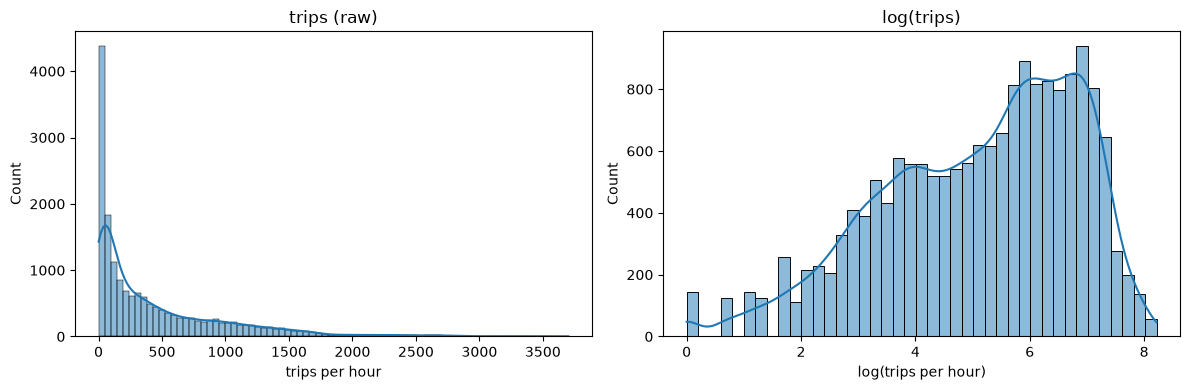

In [288]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(panel25['trips'], kde=True, ax=axes[0])
axes[0].set_title('trips (raw)')
axes[0].set_xlabel('trips per hour')

sns.histplot(np.log(panel25['trips']), kde=True, ax=axes[1])
axes[1].set_title('log(trips)')
axes[1].set_xlabel('log(trips per hour)')

plt.tight_layout()
plt.show()

#### response -> trips per station

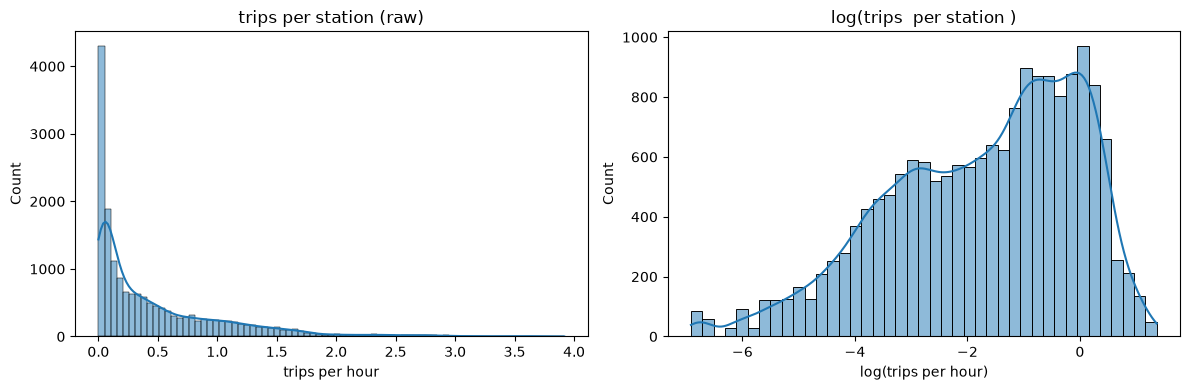

In [289]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(panel25['trips_per_station'], kde=True, ax=axes[0])
axes[0].set_title('trips per station (raw)')
axes[0].set_xlabel('trips per hour')

sns.histplot(np.log(panel25['trips_per_station']), kde=True, ax=axes[1])
axes[1].set_title('log(trips  per station )')
axes[1].set_xlabel('log(trips per hour)')

plt.tight_layout()
plt.show()

zero-inflated values, take log helps, but data still highly skewed

### user_type

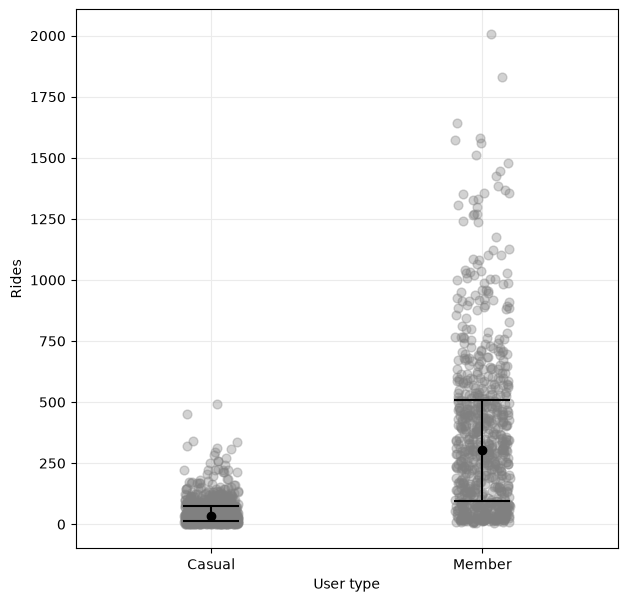

In [255]:
rng = np.random.default_rng(42)
categories = ["Casual", "Member"]
fig, ax = plt.subplots(figsize=(7, 7))

panel_sep_26 = df = panel[panel['year_month']=='2025-03']

for i, cat in enumerate(categories):
    y = panel_sep_26.loc[panel_sep_26["user_type"] == cat, "trips"].to_numpy()

    # jittered points
    x = i + rng.uniform(-0.1, 0.1, size=len(y))
    ax.scatter(x, y, s=40, color="grey", alpha=0.35, zorder=2)

    # median + interquartile range (25th–75th percentile)
    q1, med, q3 = np.percentile(y, [25, 50, 75])
    ax.errorbar(i, med, yerr=[[med - q1], [q3 - med]], fmt="o", color="black",
                capsize=20, elinewidth=1.5, capthick=1.5, zorder=3)

ax.set_xticks(range(len(categories)), categories)
ax.set_xlim(-0.5, len(categories) - 0.5)
ax.set_xlabel("User type"); ax.set_ylabel("Rides")
ax.grid(True, color="#ebebeb"); ax.set_axisbelow(True)
plt.show()

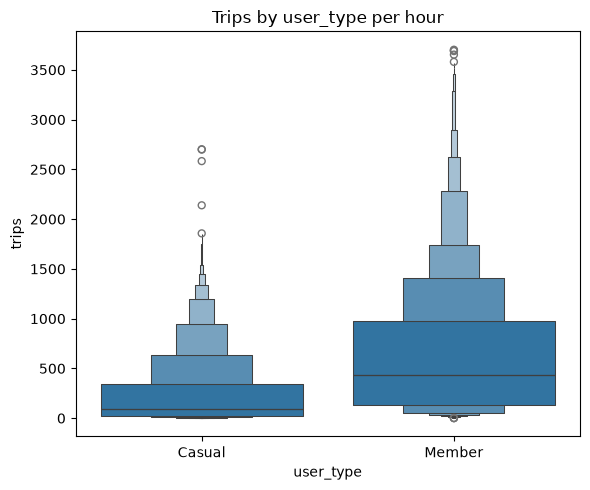

In [290]:
fig, ax = plt.subplots(figsize=(6, 5))
sns.boxenplot(data=panel25, x='user_type', y='trips', ax=ax)
ax.set_title('Trips by user_type per hour')
plt.tight_layout()
plt.show()

### month

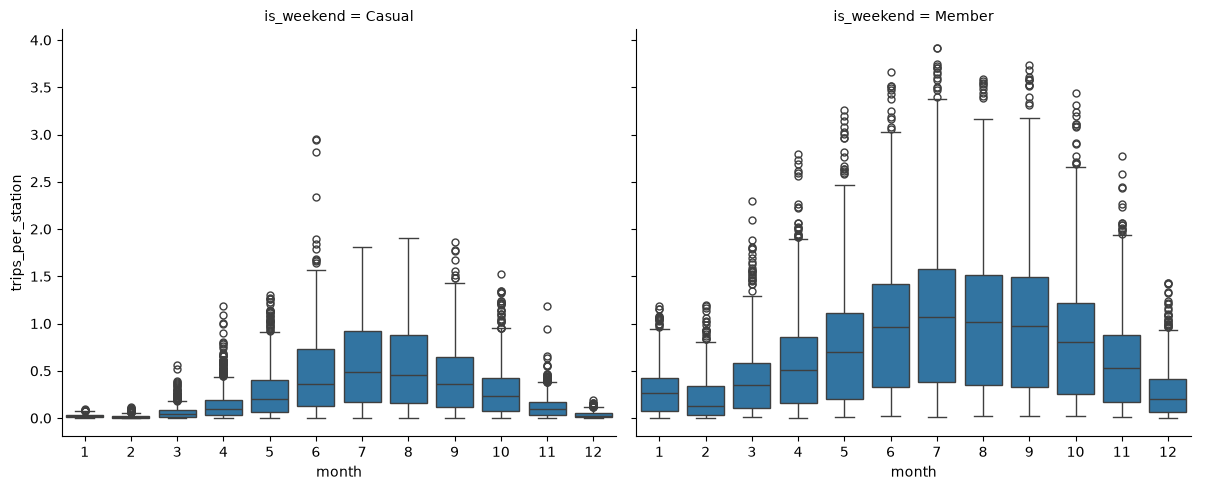

In [291]:
g = sns.catplot(
    data=panel25, x='month', y='trips_per_station',
    col='user_type', kind='box',
    height=5, aspect=1.2,
)

g.set_titles('is_weekend = {col_name}')
plt.tight_layout()
plt.show()

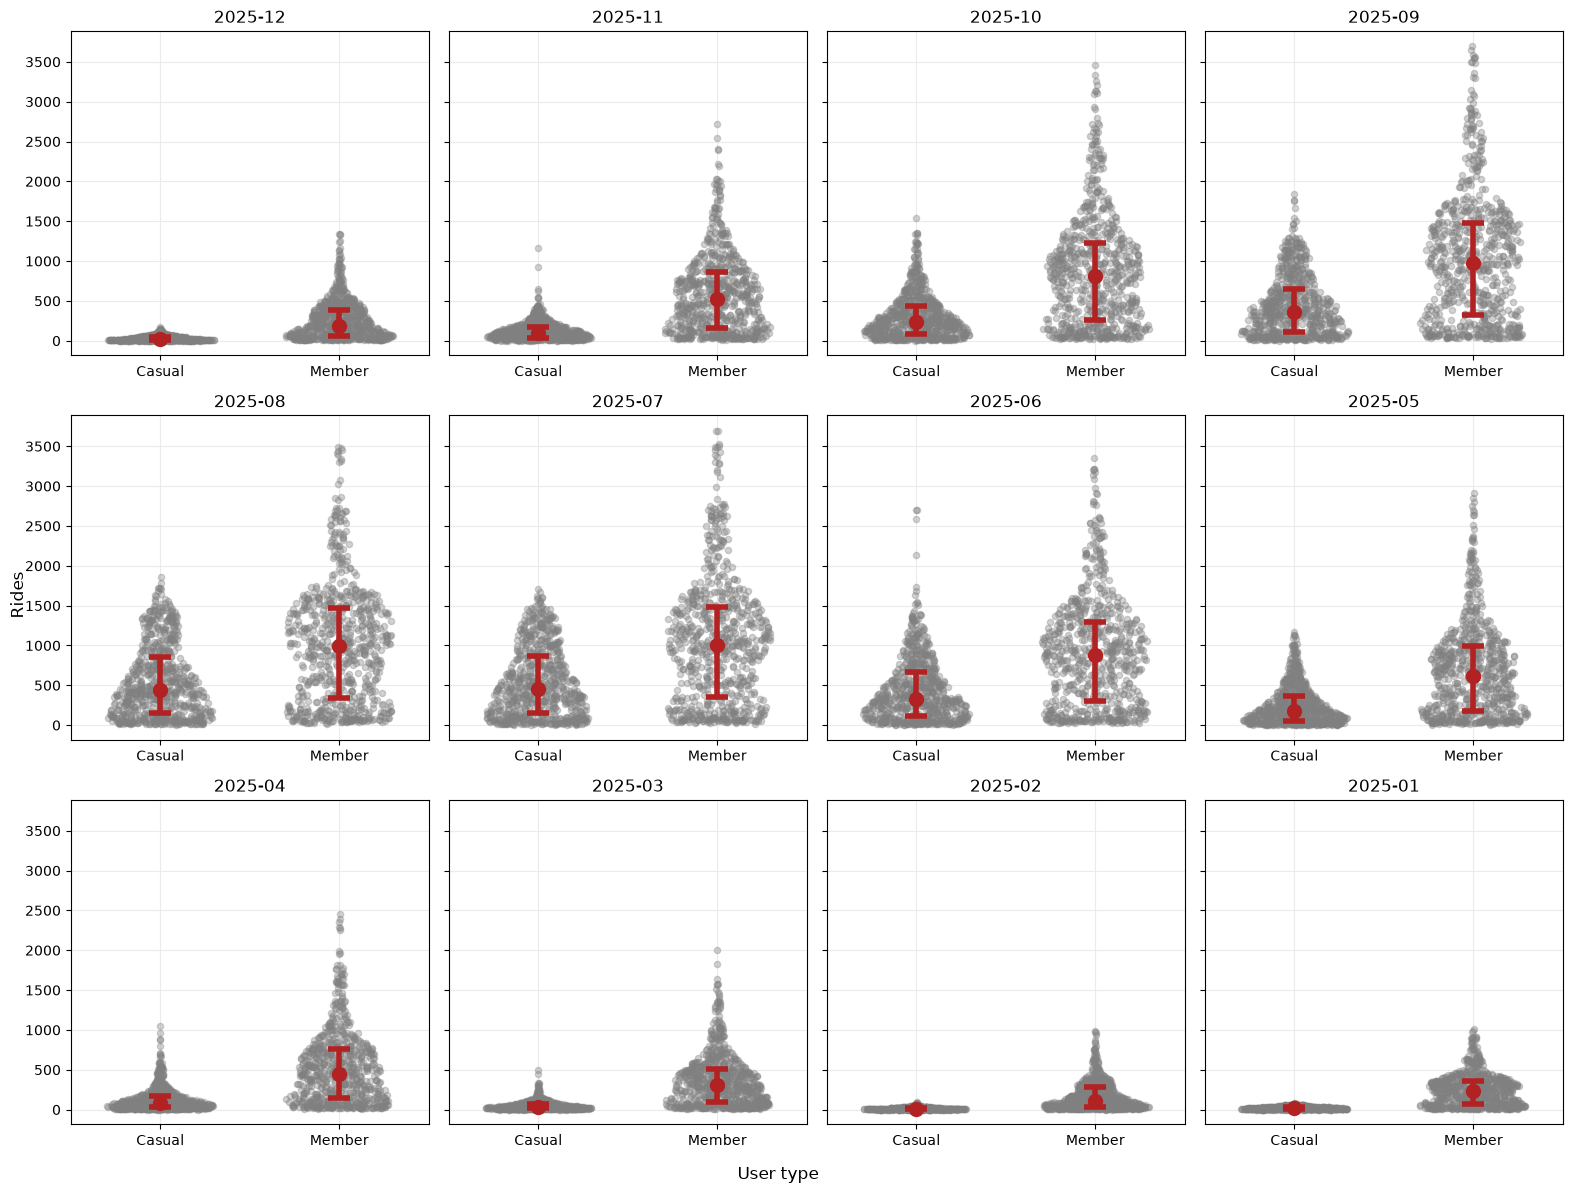

In [292]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import gaussian_kde

def violin_jitter(y, center, width=0.3, rng=None):
    """Jitter x-positions in proportion to the data density at each y."""
    rng = rng or np.random.default_rng()
    if len(y) < 2 or np.std(y) == 0:
        return center + rng.uniform(-0.05, 0.05, len(y))
    dens = gaussian_kde(y)(y)
    dens = dens / dens.max()
    return center + rng.uniform(-1, 1, len(y)) * dens * width

rng = np.random.default_rng(42)
categories = ["Casual", "Member"]

# 12 most recent months, newest first (12 → 1)
months = sorted(panel25['year_month'].unique(), reverse=True)

fig, axes = plt.subplots(3, 4, figsize=(16, 12), sharey=True)

for ax, month in zip(axes.flat, months):
    month_df = panel[panel["year_month"] == month]

    for i, cat in enumerate(categories):
        y = month_df.loc[month_df["user_type"] == cat, "trips"].to_numpy()
        if len(y) == 0:
            continue

        # violin-shaped jittered points
        x = violin_jitter(y, i, width=0.3, rng=rng)
        ax.scatter(x, y, s=20, color="grey", alpha=0.35, zorder=2)

        # median + IQR
        q1, med, q3 = np.percentile(y, [25, 50, 75])
        ax.errorbar(i, med, yerr=[[med - q1], [q3 - med]], fmt="o",
                    color="#B22222", markersize=10,
                    capsize=8, elinewidth=4, capthick=4, zorder=3)

    ax.set_title(month)
    ax.set_xticks(range(len(categories)), categories)
    ax.set_xlim(-0.5, len(categories) - 0.5)
    ax.grid(True, color="#ebebeb"); ax.set_axisbelow(True)

for ax in axes.flat[len(months):]:
    ax.set_visible(False)

fig.supxlabel("User type")
fig.supylabel("Rides")
plt.tight_layout()
plt.show()

In [279]:
# rng = np.random.default_rng(42)
# categories = ["Member", "Casual"]

# # 12 most recent months, newest first (12 → 1)
# months = sorted(panel["year_month"].astype(str).unique(), reverse=True)[:12]

# fig, axes = plt.subplots(3, 4, figsize=(16, 12), sharey=True)

# for ax, month in zip(axes.flat, months):
#     month_df = panel[panel["year_month"].astype(str) == month]

#     for i, cat in enumerate(categories):
#         y = month_df.loc[month_df["user_type"] == cat, "trips"].to_numpy()
#         if len(y) == 0:
#             continue

#         # jittered points
#         x = i + rng.uniform(-0.1, 0.1, size=len(y))
#         ax.scatter(x, y, s=20, color="grey", alpha=0.35, zorder=2)

#         # median (black) + interquartile range (red) color="#B22222"
#         q1, med, q3 = np.percentile(y, [25, 50, 75])
#         ax.errorbar(i, med, yerr=[[med - q1], [q3 - med]], fmt="o",
#                     color="#B22222", ecolor="#B22222",
#                     capsize=12, elinewidth=1.5, capthick=1.5, zorder=3)

#     ax.set_title(month)
#     ax.set_xticks(range(len(categories)), categories)
#     ax.set_xlim(-0.5, len(categories) - 0.5)
#     ax.grid(True, color="#ebebeb"); ax.set_axisbelow(True)

# # Hide unused panels if there are fewer than 12 months
# for ax in axes.flat[len(months):]:
#     ax.set_visible(False)

# fig.supxlabel("User type")
# fig.supylabel("Rides")
# plt.tight_layout()
# plt.show()

### dow

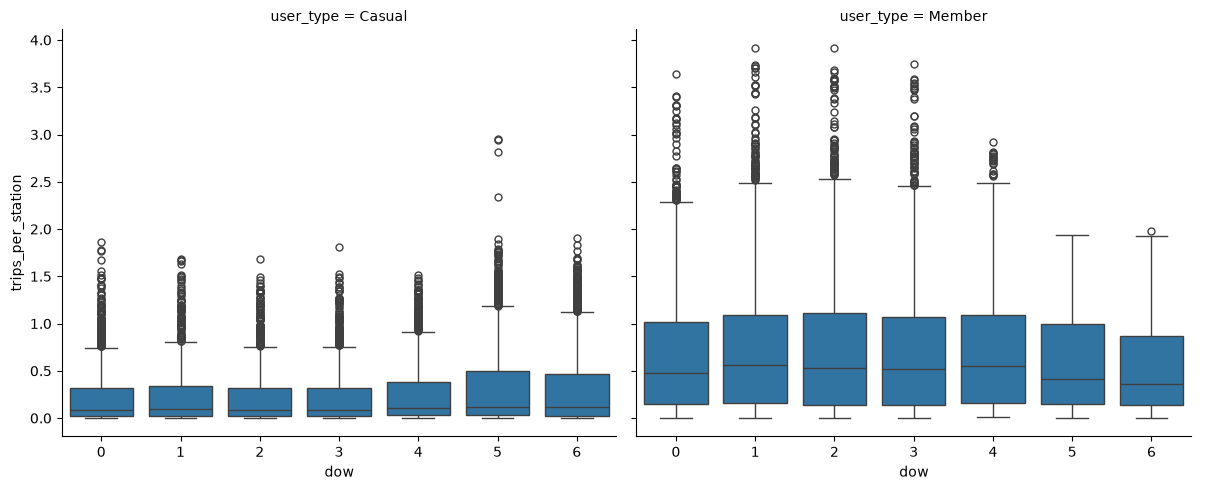

In [293]:
sns.catplot(
    data=panel25, x='dow', y='trips_per_station',
    col='user_type', kind='box',
    height=5, aspect=1.2,
)

g.set_titles('is_weekend = {col_name}')
plt.tight_layout()
plt.show()

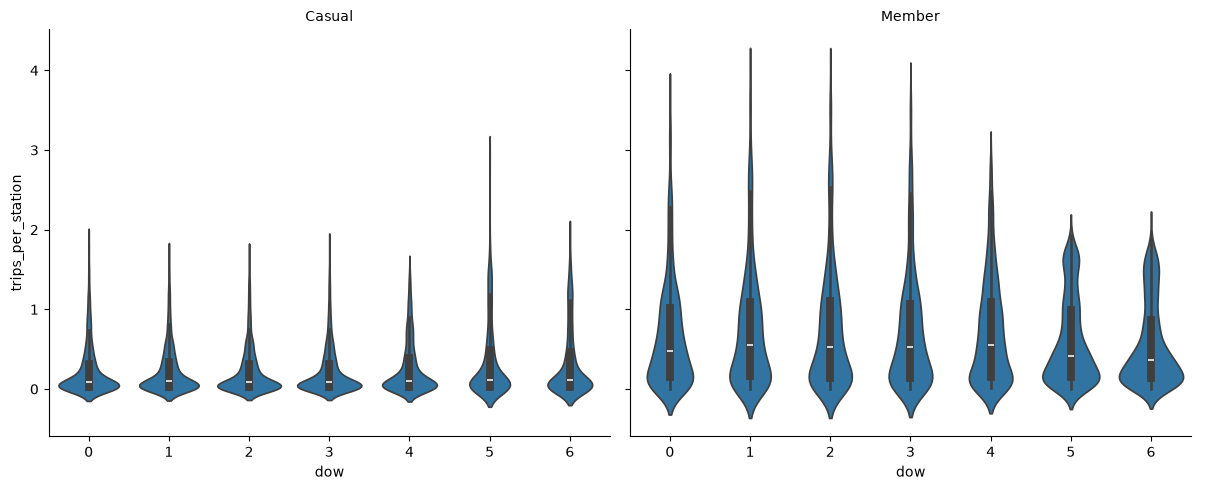

In [294]:
g = sns.catplot(
    data=panel25, x='dow', y='trips_per_station',
    col='user_type', kind='violin',
    height=5, aspect=1.2,
)
g.set_titles('{col_name}')
plt.tight_layout()
plt.show()

### hour with is_weekend (workday)

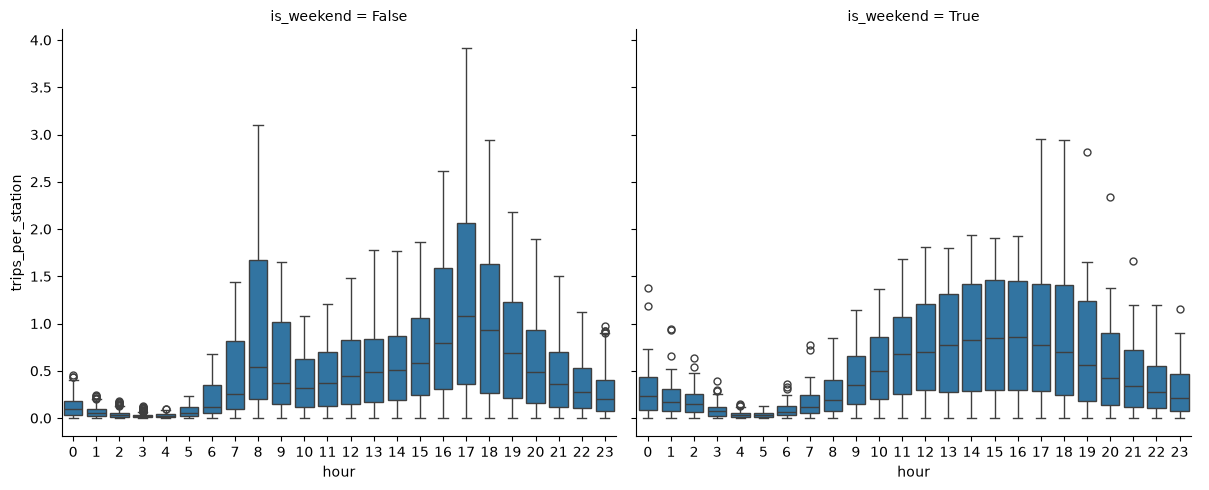

In [295]:
g = sns.catplot(
    data=panel25, x='hour', y='trips_per_station',
    col='is_weekend', kind='box',
    height=5, aspect=1.2,
)
g.set_titles('is_weekend = {col_name}')
plt.tight_layout()
plt.show()

2 peaks at around 8 and 17 - 
low, tight boxes overnight (2–5am), a rise through the morning with a peak around hour 8, a dip (but not down to overnight lows) through midday, then the biggest peak around hour 17 — matching the IRR pattern you already saw in the NB model (hour 17 ≈ 6.2x baseline, hour 8 ≈ 4.3x). Also watch the box heights (spread), not just the medians — rush hours will likely show wider boxes/more outliers than overnight hours, which is more visible evidence of the heteroscedasticity (variance growing with the mean) that motivated moving away from OLS in the first place.

### workday

In [282]:
panel.columns

Index(['date_hour', 'user_type', 'trips', 'year_month', 'active_stations',
       'date', 'is_holiday', 'dow', 'month', 'hour', 'is_weekend', 'workday',
       'temp_c', 'precip_mm', 'snowfall_cm', 'wind_kph', 'trips_per_station'],
      dtype='str')

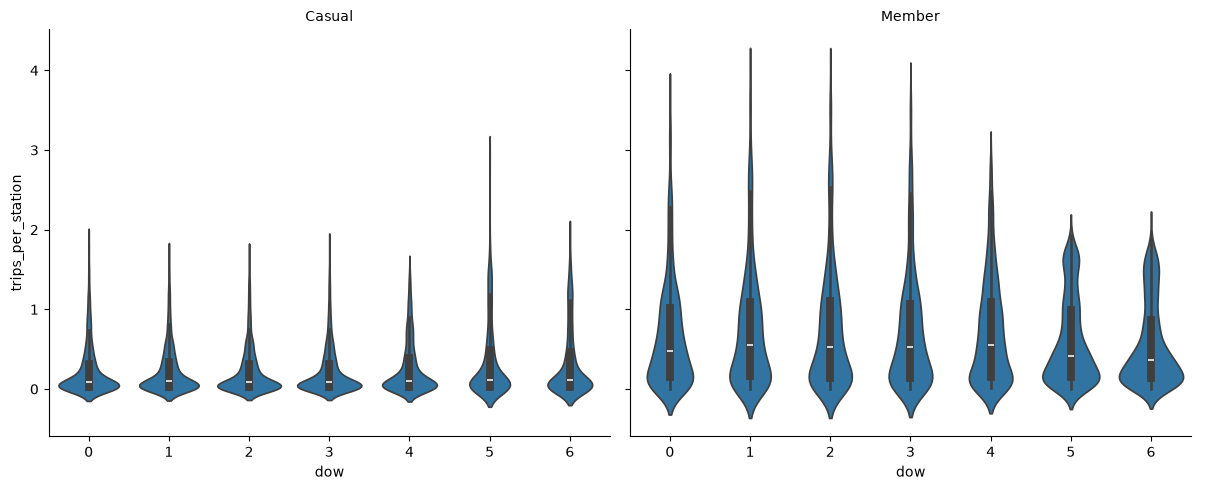

In [296]:
g = sns.catplot(
    data=panel25, x='dow', y='trips_per_station',
    col='user_type', kind='violin',
    height=5, aspect=1.2,
)
g.set_titles('{col_name}')
plt.tight_layout()
plt.show()

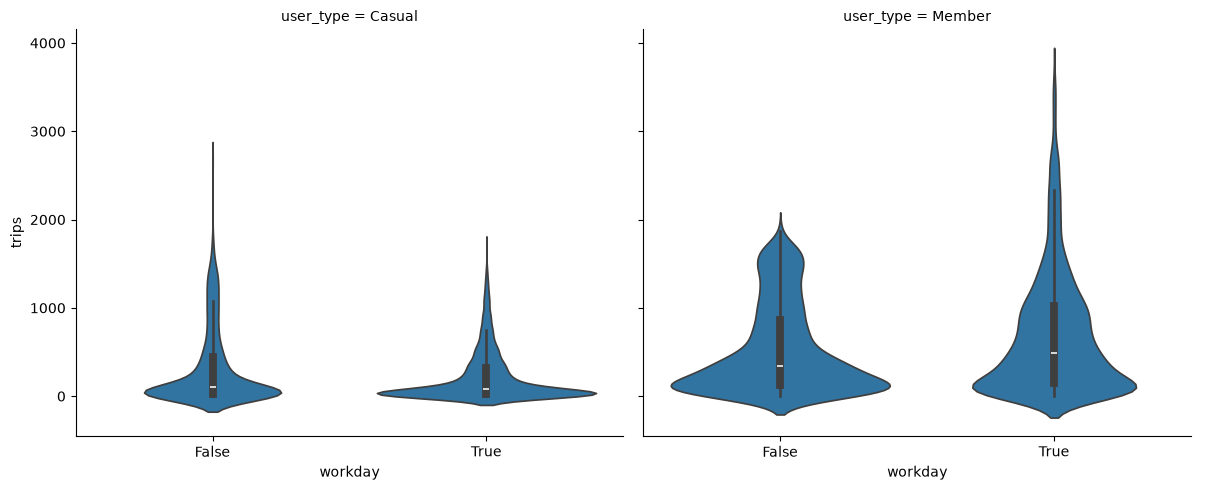

In [297]:
sns.catplot(
    data=panel25, x='workday', y='trips',
    col='user_type', kind='violin',
    height=5, aspect=1.2,
)

g.set_titles('is_weekend = {col_name}')
plt.tight_layout()
plt.show()

In [300]:
panel25.head()

,date_hour,user_type,trips,year_month,active_stations,date,is_holiday,dow,month,hour,is_weekend,workday,temp_c,precip_mm,snowfall_cm,wind_kph,trips_per_station
137699,2025-01-01 00:00:00,Casual,51,2025-01,848,2025-01-01,True,2,1,0,False,False,3.3,0.0,0.0,14.0,0.060142
137700,2025-01-01 00:00:00,Member,138,2025-01,848,2025-01-01,True,2,1,0,False,False,3.3,0.0,0.0,14.0,0.162736
137701,2025-01-01 01:00:00,Casual,50,2025-01,848,2025-01-01,True,2,1,1,False,False,2.8,0.0,0.0,15.2,0.058962
137702,2025-01-01 01:00:00,Member,128,2025-01,848,2025-01-01,True,2,1,1,False,False,2.8,0.0,0.0,15.2,0.150943
137703,2025-01-01 02:00:00,Casual,35,2025-01,848,2025-01-01,True,2,1,2,False,False,2.3,0.0,0.0,17.9,0.041274


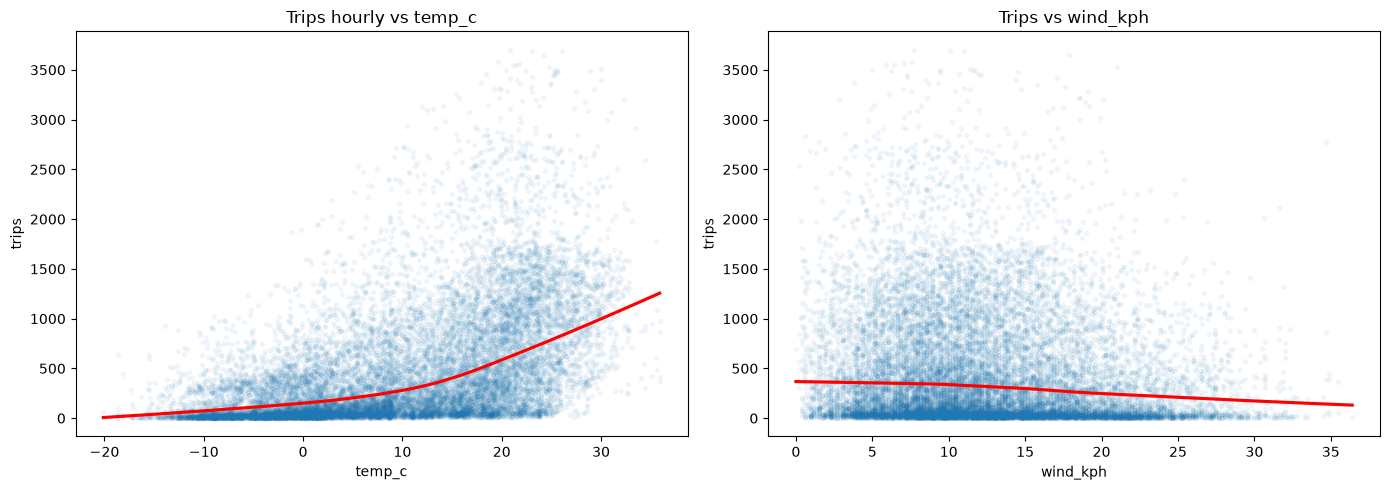

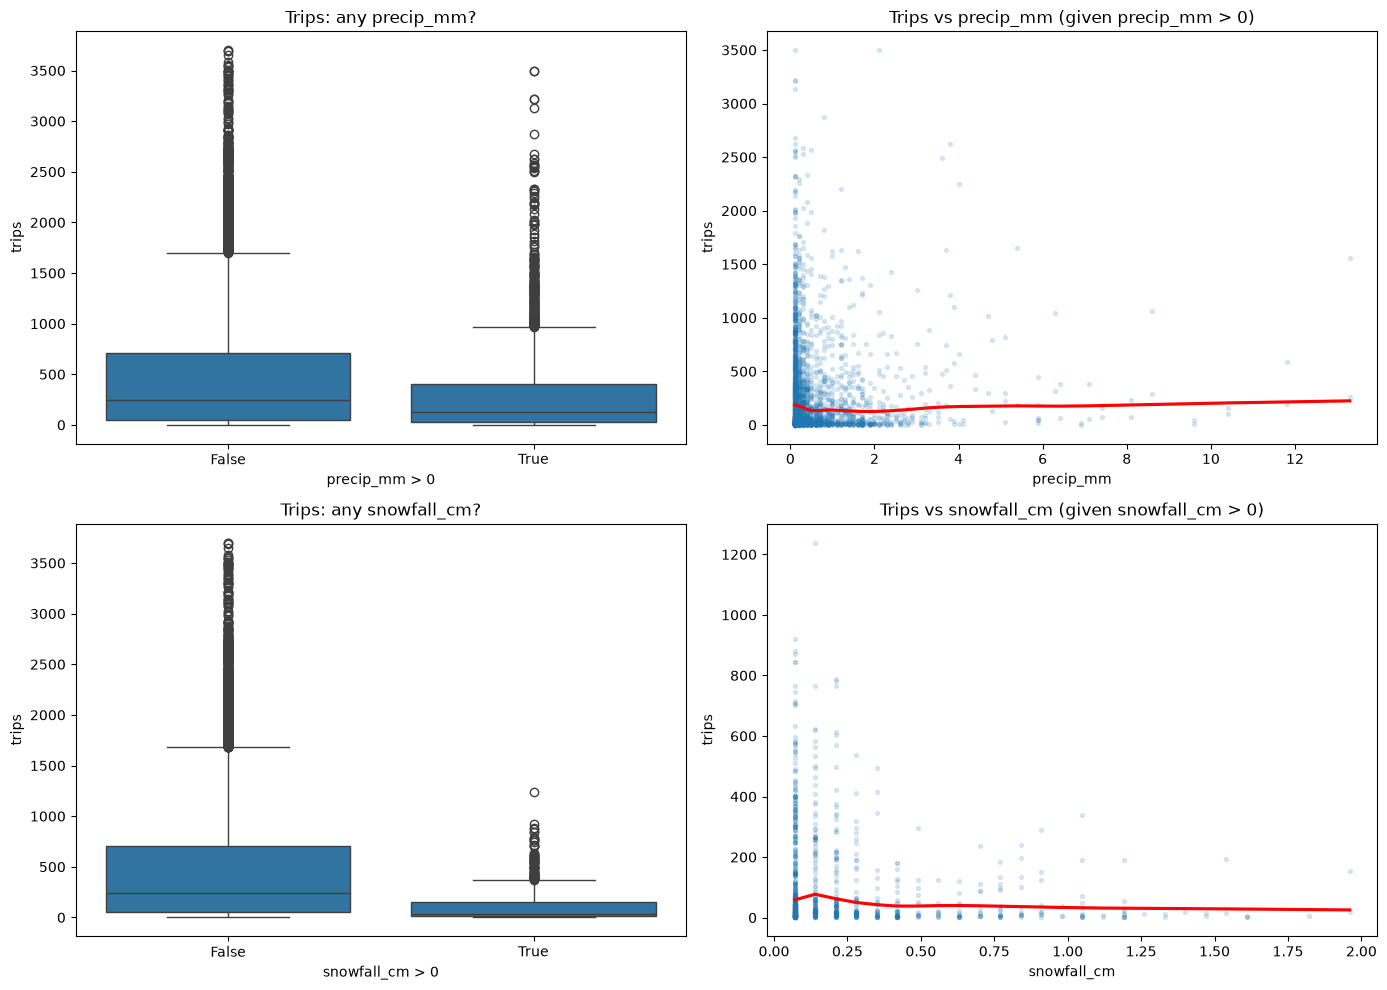

In [302]:
# temp_c and wind_kph - continuous, not zero-inflated: scatter + LOWESS smoother,
# low alpha to handle ~88k overplotted points
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.regplot(data=panel25, x='temp_c', y='trips', ax=axes[0],
            scatter_kws={'alpha': 0.05, 's': 8}, lowess=True, line_kws={'color': 'red'})
axes[0].set_title('Trips hourly vs temp_c')

sns.regplot(data=panel25, x='wind_kph', y='trips', ax=axes[1],
            scatter_kws={'alpha': 0.05, 's': 8}, lowess=True, line_kws={'color': 'red'})
axes[1].set_title('Trips vs wind_kph')

plt.tight_layout()
plt.show()

# precip_mm and snowfall_cm - zero-inflated: split "did it happen at all" from
# "how much, given it happened"
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

for row, col_name in enumerate(['precip_mm', 'snowfall_cm']):
    is_present = panel25[col_name] > 0

    sns.boxplot(x=is_present, y=panel25['trips'], ax=axes[row, 0])
    axes[row, 0].set_xlabel(f'{col_name} > 0')
    axes[row, 0].set_title(f'Trips: any {col_name}?')

    sns.regplot(data=panel25[is_present], x=col_name, y='trips', ax=axes[row, 1],
                scatter_kws={'alpha': 0.15, 's': 8}, lowess=True, line_kws={'color': 'red'})
    axes[row, 1].set_title(f'Trips vs {col_name} (given {col_name} > 0)')

plt.tight_layout()
plt.show()

## Linear Regression

In [88]:
# panel['trips_per_station'] = panel['trips'] / panel['active_stations']

In [204]:
# prepare design matrix:
X = pd.get_dummies(
        panel[['month', 'dow', 'hour', 'user_type']].astype('category'),
        drop_first=True, 
        )
X = pd.concat([X, panel[['workday', 'temp_c', 'precip_mm', 'snowfall_cm', 'wind_kph']]], axis=1)
X = sm.add_constant(X)
X.head()

,const,month_2,month_3,month_4,month_5,month_6,month_7,month_8,month_9,month_10,...,hour_20,hour_21,hour_22,hour_23,user_type_Member,workday,temp_c,precip_mm,snowfall_cm,wind_kph
0,1.0,False,False,False,False,False,True,False,False,False,...,False,False,False,False,False,False,19.4,0.0,0.0,8.5
1,1.0,False,False,False,False,False,True,False,False,False,...,False,False,False,False,True,False,19.4,0.0,0.0,8.5
2,1.0,False,False,False,False,False,True,False,False,False,...,False,False,False,False,False,False,18.8,0.0,0.0,10.1
3,1.0,False,False,False,False,False,True,False,False,False,...,False,False,False,False,True,False,18.8,0.0,0.0,10.1
4,1.0,False,False,False,False,False,True,False,False,False,...,False,False,False,False,False,False,18.3,0.0,0.0,9.5


In [304]:
panel25.shape

(17396, 17)

In [303]:
ols_model = smf.ols(
    "trips ~ C(user_type, Treatment(reference='Member'))"
    " + C(month) + C(dow) + C(hour) + workday + temp_c + precip_mm + snowfall_cm + wind_kph",
    data=panel25
).fit()
print(ols_model.summary())

                            OLS Regression Results                            
Dep. Variable:                  trips   R-squared:                       0.667
Model:                            OLS   Adj. R-squared:                  0.666
Method:                 Least Squares   F-statistic:                     754.4
Date:                Thu, 19 Nov 2026   Prob (F-statistic):               0.00
Time:                        15:19:52   Log-Likelihood:            -1.2502e+05
No. Observations:               17396   AIC:                         2.501e+05
Df Residuals:                   17349   BIC:                         2.505e+05
Df Model:                          46                                         
Covariance Type:            nonrobust                                         
                                                            coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------------

In [353]:
summary = ols_model.summary()
print(summary.tables[0])
print(summary.tables[2])

                            OLS Regression Results                            
Dep. Variable:                  trips   R-squared:                       0.667
Model:                            OLS   Adj. R-squared:                  0.666
Method:                 Least Squares   F-statistic:                     754.4
Date:                Thu, 19 Nov 2026   Prob (F-statistic):               0.00
Time:                        16:54:55   Log-Likelihood:            -1.2502e+05
No. Observations:               17396   AIC:                         2.501e+05
Df Residuals:                   17349   BIC:                         2.505e+05
Df Model:                          46                                         
Covariance Type:            nonrobust                                         
Omnibus:                     4753.144   Durbin-Watson:                   1.723
Prob(Omnibus):                  0.000   Jarque-Bera (JB):            19629.301
Skew:                           1.298   Prob(JB):   

- Quite descent adjusted R2 (0.666), 
- F statistic is huge (754.4), so model explains something 
- 2 tests (Omnibus/Jarque-Bera (JB)) on normality strongly reject normality assumption
- high skew (1.298) - residuals are assymetric
- high kurtosis (7.511)- much heavier tails then normal
- Durbin-Watson: there is autocorelation with lag-1, what is expected, we deal with time series data

### Interpret the results

In [341]:
estim_tbl = pd.concat([ols_model.params.rename('coef'), ols_model.pvalues.rename('pvalue')], axis=1)
estim_tbl.sort_values('pvalue', ascending=False).head()

,coef,pvalue
C(month)[T.4],7.987452,0.564533
C(month)[T.12],-15.445207,0.195337
C(hour)[T.6],26.643285,0.113505
C(month)[T.3],-27.975498,0.025520
C(dow)[T.3],23.683190,0.009787


### let's look at the residuals:

In [319]:
# plot the residuals:

fitted = ols_model.fittedvalues
resid = ols_model.resid 


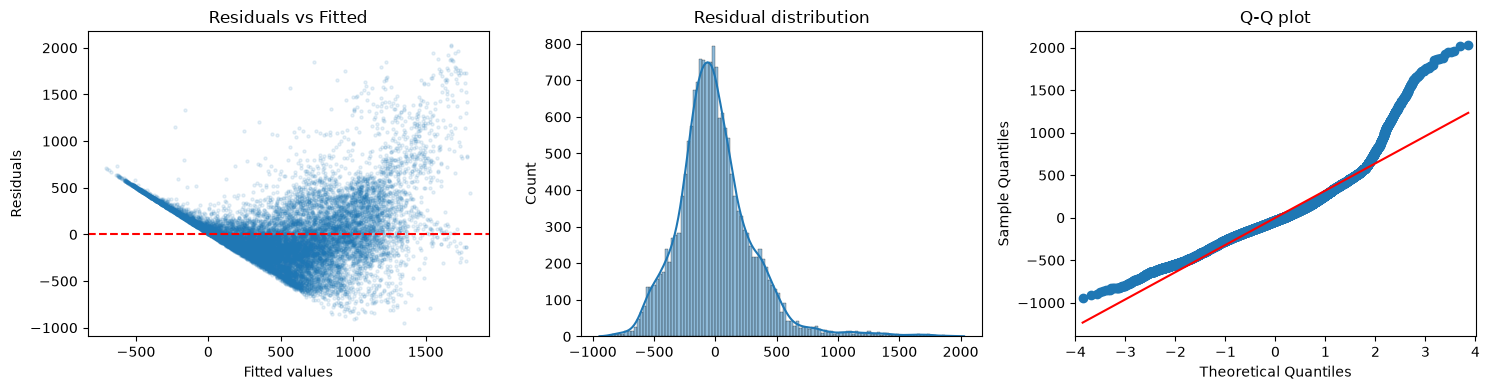

In [342]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# 1. Residuals vs fitted 
axes[0].scatter(fitted, resid, alpha=0.1, s=5)
axes[0].axhline(0, color='red', linestyle='--')
axes[0].set_xlabel('Fitted values')
axes[0].set_ylabel('Residuals')
axes[0].set_title('Residuals vs Fitted')

# 2. Histogram 
sns.histplot(resid, kde=True, ax=axes[1])
axes[1].set_title('Residual distribution')

# 3. Q-Q plot 
from statsmodels.graphics.gofplots import qqplot
qqplot(resid, line='s', ax=axes[2])
axes[2].set_title('Q-Q plot')

plt.tight_layout()
plt.show()

### Can we belive that results? 

### what's wrong with the model:


In [345]:
# 2928 fitted values are negative, when real counts can't go negative. 
fitted[fitted<0].shape

(2928,)

### assumptions' violations

- Heteroscedasticity - Residuals vs fitted plot shows a cone shape (variance increasing with fitted value)


- Residual Histogram and Q-Q plot shows that residuals are right-skew (long right tail), and there are heavy tails in the Q-Q plot deviating from the 45 degree line, especially at the top end.


### We have 2 ways how to improve the result: we can modify the data or we can modify the model. Let's try to transform the data.

### Transformation

In [346]:
ols_log_model = smf.ols(
    "np.log(trips) ~ C(user_type, Treatment(reference='Member'))"
    " + C(month) + C(dow) + C(hour) + workday + temp_c + precip_mm + snowfall_cm + wind_kph",
    data=panel25,
).fit()


In [352]:
ols_log_model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:          np.log(trips)   R-squared:                       0.854
Model:                            OLS   Adj. R-squared:                  0.854
Method:                 Least Squares   F-statistic:                     2210.
Date:                Thu, 19 Nov 2026   Prob (F-statistic):               0.00
Time:                        16:48:06   Log-Likelihood:                -17343.
No. Observations:               17396   AIC:                         3.478e+04
Df Residuals:                   17349   BIC:                         3.515e+04
Df Model:                          46                                         
Covariance Type:            nonrobust                                         
=========================================================================================================================
                                                            coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------------------------------------------
Intercept                                                 3.9073      0.047     83.157      0.000       3.815       3.999
C(user_type, Treatment(reference='Member'))[T.Casual]    -1.4396      0.010   -144.548      0.000      -1.459      -1.420
C(month)[T.2]                                            -0.5275      0.025    -20.803      0.000      -0.577      -0.478
C(month)[T.3]                                             0.2152      0.026      8.380      0.000       0.165       0.266
C(month)[T.4]                                             0.5799      0.028     20.398      0.000       0.524       0.636
C(month)[T.5]                                             0.8230      0.032     25.398      0.000       0.760       0.887
C(month)[T.6]                                             0.9476      0.040     23.963      0.000       0.870       1.025
C(month)[T.7]                                             0.9632      0.043     22.288      0.000       0.879       1.048
C(month)[T.8]                                             1.0694      0.040     26.418      0.000       0.990       1.149
C(month)[T.9]                                             1.0545      0.038     27.875      0.000       0.980       1.129
C(month)[T.10]                                            1.0860      0.032     33.861      0.000       1.023       1.149
C(month)[T.11]                                            0.8376      0.027     31.286      0.000       0.785       0.890
C(month)[T.12]                                            0.0503      0.024      2.057      0.040       0.002       0.098
C(dow)[T.1]                                               0.0565      0.019      3.010      0.003       0.020       0.093
C(dow)[T.2]                                               0.0345      0.019      1.846      0.065      -0.002       0.071
C(dow)[T.3]                                               0.0238      0.019      1.267      0.205      -0.013       0.061
C(dow)[T.4]                                               0.1394      0.019      7.445      0.000       0.103       0.176
C(dow)[T.5]                                               0.5456      0.036     15.147      0.000       0.475       0.616
C(dow)[T.6]                                               0.4271      0.036     11.848      0.000       0.356       0.498
C(hour)[T.1]                                             -0.5125      0.035    -14.832      0.000      -0.580      -0.445
C(hour)[T.2]                                             -0.7950      0.035    -22.967      0.000      -0.863      -0.727
C(hour)[T.3]                                             -1.3993      0.035    -40.166      0.000      -1.468      -1.331
C(hour)[T.4]                     

In [ ]:
# High adj. R2-squared 0.854
# huge F statistics - 2210
# skewness almost gone
# Kurtosis became smaller, but still quite heavy

### assumptions' violations

In [311]:
log_fitted = ols_log_model.fittedvalues
log_resid = ols_log_model.resid 


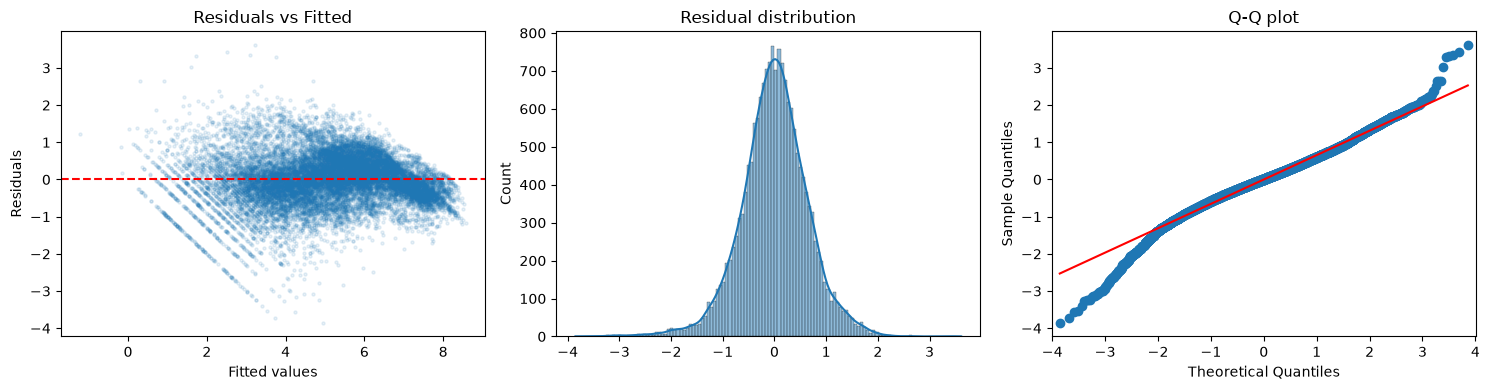

In [350]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# 1. Residuals vs fitted 
axes[0].scatter(log_fitted, log_resid, alpha=0.1, s=5)
axes[0].axhline(0, color='red', linestyle='--')
axes[0].set_xlabel('Fitted values')
axes[0].set_ylabel('Residuals')
axes[0].set_title('Residuals vs Fitted')

# 2. Histogram 
sns.histplot(log_resid, kde=True, ax=axes[1])
axes[1].set_title('Residual distribution')

# 3. Q-Q plot 
from statsmodels.graphics.gofplots import qqplot
qqplot(log_resid, line='s', ax=axes[2])
axes[2].set_title('Q-Q plot')

plt.tight_layout()
plt.show()

### Residual diagnostics (log scale)

**Overall:** The log transform worked well. Residuals are centered at 0 with no overall bias, and roughly 95% of them look close to normal.

**Key findings**
- **Distribution:** Symmetric around 0 but more peaked than normal, with fatter tails. The left tail (down to −4) is longer than the right (up to about +3.5).
- **Q-Q plot:** Points follow the line from about −2 to +3. The lower tail falls well below it, meaning large overpredictions.
- **Low counts:** The diagonal stripes in the residuals-vs-fitted plot are small true counts (0, 1, 2) that the model predicts too high. These cause the heavy left tail.
- **Uneven spread:** The residuals are widest at fitted values of 1–4 and narrowest at 7–8, so the variance isn't constant.
- **High end:** The model slightly overpredicts above a fitted value of about 6.5.

**Implications**
- Predictions are reliable for typical and high-volume cases. They're weakest for low counts.
- Use robust standard errors (HC3) for any inference.

**Next steps**
1. Try a Poisson or negative binomial model, which handles low counts and uneven spread better.
2. Look at the rows with residuals below −2 for shared patterns (time, category, conditions).
3. Add nonlinear terms or interactions to fix the overprediction at the high end.

## GLM

### Poisson Regression for Counts. Where mean = variance

offset for trips/stations:

https://medium.com/data-science/offsetting-the-model-logic-to-implementation-7e333bc25798

offset is a term in the GLM formula whose coefficient is forced to exactly 1 instead of being estimated. It exists specifically to handle "exposure" — when your counts naturally scale with something external that isn't itself a thing you want the model to explain.

The problem it solves here: a Poisson/NB model predicts trips as some function of your predictors. If a station-month has 200 stations vs. a later month with 1,000 stations, you'd expect roughly 5x more trips just from the fleet being bigger — nothing to do with weather or time-of-day. Without correcting for that, the model would blame fleet growth on whatever predictor happens to trend upward over the same years (and your trips-over-time trend absolutely does, since the network grew 5x).

Why log(active_stations) specifically: a Poisson/NB GLM models the log of the expected count:

log(E[trips]) = β₀ + β₁·temp_c + β₂·precip_mm + ...

Adding an offset just appends one more term with its coefficient fixed at 1:

log(E[trips]) = β₀ + β₁·temp_c + ... + 1·log(active_stations)

Exponentiate both sides and the log(active_stations) term becomes a plain multiplication:

E[trips] = active_stations × exp(β₀ + β₁·temp_c + ...)

So the model is really saying: trips = (number of stations) × (trips per station, as a function of weather/time). The exp(β₀ + β₁·temp_c + ...) part — the thing the model actually estimates — is trips-per-station, with fleet size divided out before any coefficient gets fit. That's why all the IRRs we read earlier (exp(coef)) could be interpreted as "percent change in trips per station," not "percent change in raw trip count."

Contrast with a normal predictor: if you'd written + active_stations as a regular term instead of an offset, the model would estimate its coefficient — e.g. it might find each extra station adds some number of trips, not necessarily proportionally. Using offset= instead says "I already know the relationship is exactly proportional (1 extra station → proportionally more trips), so don't spend a parameter estimating that — just divide it out and fit everything else on the per-station rate."

One concrete way to see it: trips / active_stations (what we used as the dependent variable in the plain OLS version) and offset=log(active_stations) in the Poisson/NB version are doing the same conceptual job — forcing the model onto a per-station scale — just via division in OLS vs. a fixed-coefficient log-term in the GLM, because GLMs work on the log scale rather than the raw scale.

https://datasciencecampus.github.io/af_stats_python/course_content/Chapter%203%20-%20Generalised%20Linear%20Models.html

In [313]:
import statsmodels.api as sm
import statsmodels.formula.api as smf

In [314]:
panel25.head()

,date_hour,user_type,trips,year_month,active_stations,date,is_holiday,dow,month,hour,is_weekend,workday,temp_c,precip_mm,snowfall_cm,wind_kph,trips_per_station
137699,2025-01-01 00:00:00,Casual,51,2025-01,848,2025-01-01,True,2,1,0,False,False,3.3,0.0,0.0,14.0,0.060142
137700,2025-01-01 00:00:00,Member,138,2025-01,848,2025-01-01,True,2,1,0,False,False,3.3,0.0,0.0,14.0,0.162736
137701,2025-01-01 01:00:00,Casual,50,2025-01,848,2025-01-01,True,2,1,1,False,False,2.8,0.0,0.0,15.2,0.058962
137702,2025-01-01 01:00:00,Member,128,2025-01,848,2025-01-01,True,2,1,1,False,False,2.8,0.0,0.0,15.2,0.150943
137703,2025-01-01 02:00:00,Casual,35,2025-01,848,2025-01-01,True,2,1,2,False,False,2.3,0.0,0.0,17.9,0.041274


### fit Poisson

In [221]:
poisson_model = smf.glm(
    "trips ~ C(user_type, Treatment(reference='Member')) + C(month) + C(dow) + C(hour) + workday + temp_c + precip_mm + snowfall_cm + wind_kph",
    data=panel,
    family=sm.families.Poisson(),
    offset=np.log(panel['active_stations']),
).fit()
print(poisson_model.summary())
print("Pearson chi2 / df_resid:", poisson_model.pearson_chi2 / poisson_model.df_resid)

                 Generalized Linear Model Regression Results                  
Dep. Variable:                  trips   No. Observations:               168058
Model:                            GLM   Df Residuals:                   168011
Model Family:                 Poisson   Df Model:                           46
Link Function:                    Log   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:            -1.1145e+07
Date:                Wed, 18 Nov 2026   Deviance:                   2.1238e+07
Time:                        17:15:52   Pearson chi2:                 2.37e+07
No. Iterations:                     7   Pseudo R-squ. (CS):              1.000
Covariance Type:            nonrobust                                         
                                                            coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------------

### interpret Poisson

In [222]:
poisson_model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                 Generalized Linear Model Regression Results                  
==============================================================================
Dep. Variable:                  trips   No. Observations:               168058
Model:                            GLM   Df Residuals:                   168011
Model Family:                 Poisson   Df Model:                           46
Link Function:                    Log   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:            -1.1145e+07
Date:                Wed, 18 Nov 2026   Deviance:                   2.1238e+07
Time:                        17:16:08   Pearson chi2:                 2.37e+07
No. Iterations:                     7   Pseudo R-squ. (CS):              1.000
Covariance Type:            nonrobust                                         
=========================================================================================================================
                                                            coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------------------------------------------
Intercept                                                -2.6450      0.002  -1362.936      0.000      -2.649      -2.641
C(user_type, Treatment(reference='Member'))[T.Casual]    -0.4495      0.000  -1474.130      0.000      -0.450      -0.449
C(month)[T.2]                                            -0.0020      0.001     -1.478      0.139      -0.005       0.001
C(month)[T.3]                                             0.2266      0.001    186.810      0.000       0.224       0.229
C(month)[T.4]                                             0.4574      0.001    382.026      0.000       0.455       0.460
C(month)[T.5]                                             0.7252      0.001    581.421      0.000       0.723       0.728
C(month)[T.6]                                             0.7775      0.001    568.551      0.000       0.775       0.780
C(month)[T.7]                                             0.7286      0.001    505.238      0.000       0.726       0.731
C(month)[T.8]                                             0.8212      0.001    582.577      0.000       0.818       0.824
C(month)[T.9]                                             0.8868      0.001    670.470      0.000       0.884       0.889
C(month)[T.10]                                            0.8308      0.001    683.646      0.000       0.828       0.833
C(month)[T.11]                                            0.6615      0.001    568.234      0.000       0.659       0.664
C(month)[T.12]                                            0.2057      0.001    162.861      0.000       0.203       0.208
C(dow)[T.1]                                               0.0633      0.001    110.132      0.000       0.062       0.064
C(dow)[T.2]                                               0.0963      0.001    169.163      0.000       0.095       0.097
C(dow)[T.3]                                               0.0832      0.001    145.211      0.000       0.082       0.084
C(dow)[T.4]                                               0.0856      0.001    149.877      0.000       0.084       0.087
C(dow)[T.5]                                               0.1924      0.001    160.996      0.000       0.190       0.195
C(dow)[T.6]                                               0.1014      0.001     84.446      0.000       0.099       0.104
C(hour)[T.1]                                             -0.4359      0.002   -219.615      0.000      -0.440      -0.432
C(hour)[T.2]                                             -0.7301      0.002   -333.204      0.000      -0.734      -0.726
C(hour)[T.3]                                             -1.3038      0.003   -476.494      0.000      -1.309      -1.298
C(hour)[T.4]                     

In [109]:
poisson_model = smf.glm(formula = 'trips ~ C(hour) + C(month) + C(dow) + workday + temp_c + precip_mm + snowfall_cm + wind_kph + np.log(active_stations)', 
                        data = panel, 
                        family = sm.families.Poisson()
                        ).fit()

In [110]:
print(poisson_model.summary())

                 Generalized Linear Model Regression Results                  
Dep. Variable:                  trips   No. Observations:                88794
Model:                            GLM   Df Residuals:                    88747
Model Family:                 Poisson   Df Model:                           46
Link Function:                    Log   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:            -4.4622e+06
Date:                Mon, 16 Nov 2026   Deviance:                   8.2926e+06
Time:                        10:41:26   Pearson chi2:                 9.12e+06
No. Iterations:                     7   Pseudo R-squ. (CS):              1.000
Covariance Type:            nonrobust                                         
                              coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------------
Intercept                 

In [135]:
poisson_model.fittedvalues

0          56.825440
1          35.474603
2          26.121278
3          14.519561
4          10.085874
            ...     
88789    2780.355813
88790    2214.595251
88791    1758.799300
88792    1345.109149
88793    1005.277144
Length: 88794, dtype: float64

In [224]:
poisson_fitted = poisson_model.fittedvalues
resid_pearson = poisson_model.resid_pearson
resid_deviance = poisson_model.resid_deviance


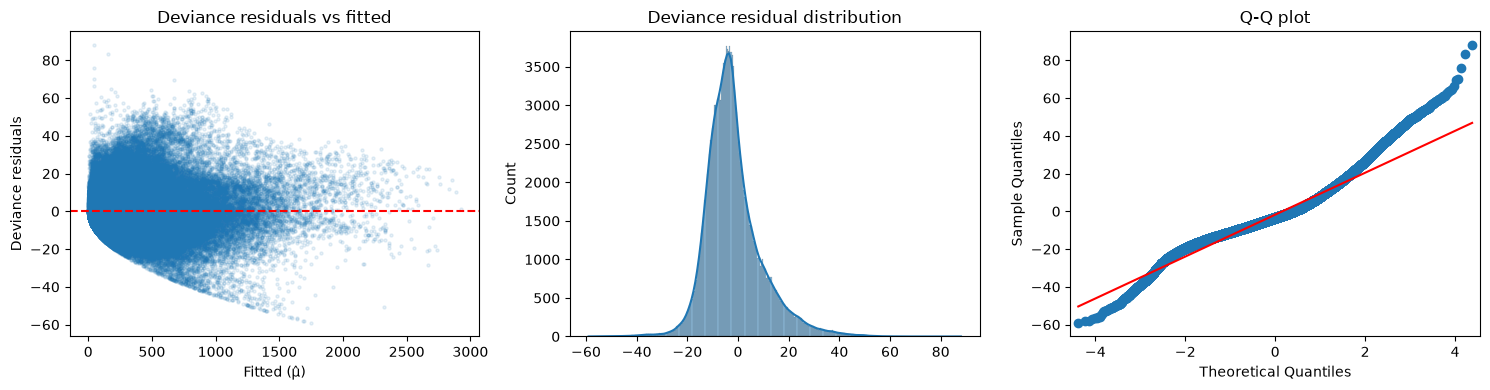

In [225]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# 1. Deviance residuals vs fitted - the standard GLM analog of "residuals vs fitted"
axes[0].scatter(poisson_fitted, resid_deviance, alpha=0.1, s=5)
axes[0].axhline(0, color='red', linestyle='--')
axes[0].set_xlabel('Fitted (μ̂)')
axes[0].set_ylabel('Deviance residuals')
axes[0].set_title('Deviance residuals vs fitted')

# 2. Distribution
sns.histplot(resid_deviance, kde=True, ax=axes[1])
axes[1].set_title('Deviance residual distribution')

# 3. Q-Q plot
from statsmodels.graphics.gofplots import qqplot
qqplot(resid_deviance, line='s', ax=axes[2])
axes[2].set_title('Q-Q plot')

plt.tight_layout()
plt.show()

In [226]:
poisson_model.pearson_chi2

np.float64(23727039.00065651)

In [227]:
print("Pearson chi2 / df_resid:", poisson_model.pearson_chi2 / poisson_model.df_resid)

Pearson chi2 / df_resid: 141.22312825146278


### Negative Binomial

In [95]:

nb_model = smf.glm(
    'trips ~ C(month) + C(dow) + C(hour) + workday + temp_c + precip_mm + snowfall_cm + wind_kph',
    data=panel,
    family=sm.families.NegativeBinomial(),
    offset=np.log(panel['active_stations']),
).fit()

print(nb_model.summary())
print("aic/Poisson:", poisson_model.aic, " negbinomial:", nb_model.aic)


/var/folders/xf/ygl5_zk57kn1rh2h1xj9fyx40000gn/T/ipykernel_97124/960514170.py:4: ValueWarning: Negative binomial dispersion parameter alpha not set. Using default value alpha=1.0.
  family=sm.families.NegativeBinomial(),


                 Generalized Linear Model Regression Results                  
Dep. Variable:                  trips   No. Observations:                88794
Model:                            GLM   Df Residuals:                    88748
Model Family:        NegativeBinomial   Df Model:                           45
Link Function:                    Log   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:            -5.7887e+05
Date:                Sun, 15 Nov 2026   Deviance:                       41669.
Time:                        23:34:18   Pearson chi2:                 4.29e+04
No. Iterations:                    63   Pseudo R-squ. (CS):             0.6573
Covariance Type:            nonrobust                                         
                      coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------
Intercept          -2.2889      0.031    -

In [ ]:
irr = np.exp(nb_model.params).rename('IRR')
irr.sort_values(ascending=False)

In [ ]:

nb_model_cl = smf.glm(
    'trips ~ C(month) + C(dow) + C(hour) + workday + temp_c + precip_mm + snowfall_cm + wind_kph',
    data=panel,
    family=sm.families.NegativeBinomial(),
    offset=np.log(panel['active_stations']),
).fit(cov_type='cluster', cov_kwds={'groups': panel['date']})

# Day-clustering handles the within-day case well but doesn't account for day-to-day persistence 
# (today's storm correlating with tomorrow's lingering effects). For that, Newey-West/HAC standard errors are the 
# more complete fix — they explicitly model how correlation decays over a specified number of lags rather than just grouping into blocks:

nb_model_hac = smf.glm(
    'trips ~ C(month) + C(dow) + C(hour) + workday + temp_c + precip_mm + snowfall_cm + wind_kph',
    data=panel,
    family=sm.families.NegativeBinomial(),
    offset=np.log(panel['active_stations']),
).fit(cov_type='HAC', cov_kwds={'maxlags': 48})  # ~2 days of hourly lags

### GAM spline for temprerature.

Worth it, but scoped narrowly — not a wholesale switch away from GLM.

Where it helps: your continuous weather terms (temp_c, precip_mm, snowfall_cm, wind_kph) are currently forced into a single linear slope across their whole range. That's the weak spot — ridership vs. temperature almost certainly isn't a straight line (probably rises up to a comfortable point then flattens or dips in extreme heat), and precip/snow likely have threshold effects (light rain barely registers, heavy rain matters a lot) rather than a constant per-mm penalty. A spline on temp_c (and maybe precip_mm) would capture that shape instead of averaging it into one slope.

Where it doesn't help: C(month), C(dow), C(hour) are already dummy-coded — that's already the most flexible possible fit for a discrete variable (one free parameter per level), so a spline there wouldn't buy you anything.

It's not GAM-vs-GLM, it's GLM-with-splines — a GAM here is just your existing Poisson/NB GLM with the linear temp_c term swapped for a spline basis; same family, same offset, same categorical terms, same smf.glm call. The smallest version of this needs no new dependency — patsy (already bundled with statsmodels) supports spline bases directly in the formula string:

'trips ~ C(month) + C(dow) + C(hour) + workday + cr(temp_c, df=4) + precip_mm + snowfall_cm + wind_kph'
(cr() = natural cubic regression spline; bs() for a B-spline basis — both from patsy, usable straight in the formula.) A fuller GAM with automatic smoothness selection would mean statsmodels.gam.generalized_additive_model.GLMGam, which is more principled but adds real complexity (choosing/cross-validating a penalty) — I'd treat that as a later refinement, not the next step.

On the time-series question — splines aren't exclusive to forecasting; they're a general nonlinear-regression tool, so using one here to fix temp_c's functional form is legitimate in this explanatory block. But you're right that GAMs show up again, differently, in a future demand-forecasting block: something like Prophet is essentially trend + seasonality + holidays all modeled as GAM smooth terms. So this block and a future time-series block aren't competing for the same tool — this block would use a spline to fix one covariate's shape inside an explanatory GLM; a forecasting block would use GAM-style smooths as the backbone for trend/seasonality in a model whose job is prediction, not coefficient interpretation.

My recommendation: add cr(temp_c, df=4) to the NB model you already have as the next incremental step, compare its AIC against the linear version, and leave the bigger GAM machinery for if/when you build the forecasting block.


## NICELY GO THROUGH LIGHT GAM COMPONENT INTO TIME SERIES PREDICTION DEMAND (AS PROPHET)

## Regressions: 

### Delta trips~ delta stations (panel + first differeciation)
### Poisson trips ~ workday + month + hour
### trip_duration ~ workday + month + hour


In [148]:
df.head()

,trip_id,start_station_id,year,start_time,user_type,start_station_name,start_neighbourhood,start_ward
0,53279,7100,2016,2016-07-09 01:03:00,Member,Dundas St E / Regent Park Blvd,Regent Park,Toronto Centre
1,53394,7097,2016,2016-07-09 02:15:00,Member,Riverdale Park North (Broadview Ave),North Riverdale,Toronto-Danforth
2,58314,7100,2016,2016-07-10 17:04:00,Member,Dundas St E / Regent Park Blvd,Regent Park,Toronto Centre
3,60784,7033,2016,2016-07-11 01:45:00,Member,Union Station,St Lawrence-East Bayfront-The Islands,Spadina-Fort York
4,93164,7059,2016,2016-07-18 13:35:00,Member,Front St W / Blue Jays Way,Harbourfront-CityPlace,Spadina-Fort York


In [ ]:
df_regr = df[~df.year.isin([2016, 2026])]

In [22]:
panel = (df_regr
            .groupby(['year', 'start_ward'], as_index=False)
            .agg(stations = ('start_station_id', 'nunique'),
                trips = ('trip_id', 'size'))
            .sort_values(['start_ward', 'year']) 
            
            .assign(stations_lag=lambda d: d.groupby('start_ward')['stations'].shift(1),
                    trips_lag=lambda d: d.groupby('start_ward')['trips'].shift(1))
            
            .assign(
                delta_stations=lambda d: d['stations'] - d['stations_lag'],
                delta_trips=lambda d: d['trips'] - d['trips_lag']
            )
            .dropna(subset=['delta_stations', 'delta_trips'])
 )

In [111]:
panel.head()

,date_hour,trips,year_month,active_stations,date,is_holiday,dow,month,hour,is_weekend,workday,temp_c,precip_mm,snowfall_cm,wind_kph
0,2016-07-01 00:00:00,125,2016-07,200,2016-07-01,True,4,7,0,False,False,19.4,0.0,0.0,8.5
1,2016-07-01 01:00:00,94,2016-07,200,2016-07-01,True,4,7,1,False,False,18.8,0.0,0.0,10.1
2,2016-07-01 02:00:00,94,2016-07,200,2016-07-01,True,4,7,2,False,False,18.3,0.0,0.0,9.5
3,2016-07-01 03:00:00,59,2016-07,200,2016-07-01,True,4,7,3,False,False,17.9,0.0,0.0,7.4
4,2016-07-01 04:00:00,56,2016-07,200,2016-07-01,True,4,7,4,False,False,17.1,0.0,0.0,9.1


In [129]:
panel.columns

Index(['date_hour', 'trips', 'year_month', 'active_stations', 'date',
       'is_holiday', 'dow', 'month', 'hour', 'is_weekend', 'workday', 'temp_c',
       'precip_mm', 'snowfall_cm', 'wind_kph'],
      dtype='str')

<Axes: ylabel='temp_c'>

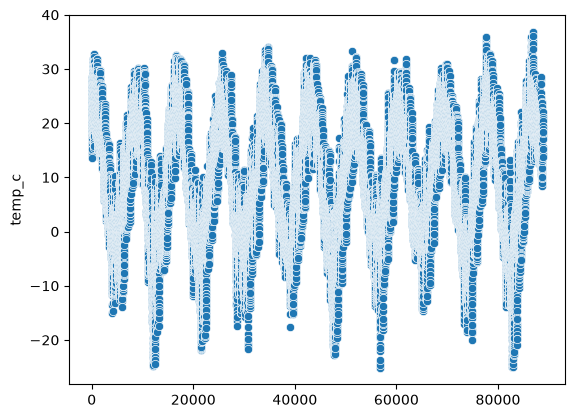

In [134]:
sns.scatterplot(panel.temp_c)

### corr matrix

In [114]:
num = panel.select_dtypes('number')

In [116]:
corr = num.corr(method='pearson')
corr

,trips,active_stations,dow,month,hour,temp_c,precip_mm,snowfall_cm,wind_kph
trips,1.000000,0.445558,-0.000617,0.137123,0.323419,0.480257,-0.063688,-0.075703,-0.100692
active_stations,0.445558,1.000000,-0.001106,0.008202,-0.001789,0.060229,0.000214,-0.004599,-0.117062
dow,-0.000617,-0.001106,1.000000,0.001430,-0.000237,-0.016399,0.000629,0.002106,0.009046
month,0.137123,0.008202,0.001430,1.000000,-0.001857,0.305475,-0.006037,-0.060982,-0.071531
hour,0.323419,-0.001789,-0.000237,-0.001857,1.000000,0.093515,-0.000949,0.008294,0.080179
temp_c,0.480257,0.060229,-0.016399,0.305475,0.093515,1.000000,0.024405,-0.133212,-0.160630
precip_mm,-0.063688,0.000214,0.000629,-0.006037,-0.000949,0.024405,1.000000,0.258683,0.102975
snowfall_cm,-0.075703,-0.004599,0.002106,-0.060982,0.008294,-0.133212,0.258683,1.000000,0.119474
wind_kph,-0.100692,-0.117062,0.009046,-0.071531,0.080179,-0.160630,0.102975,0.119474,1.000000


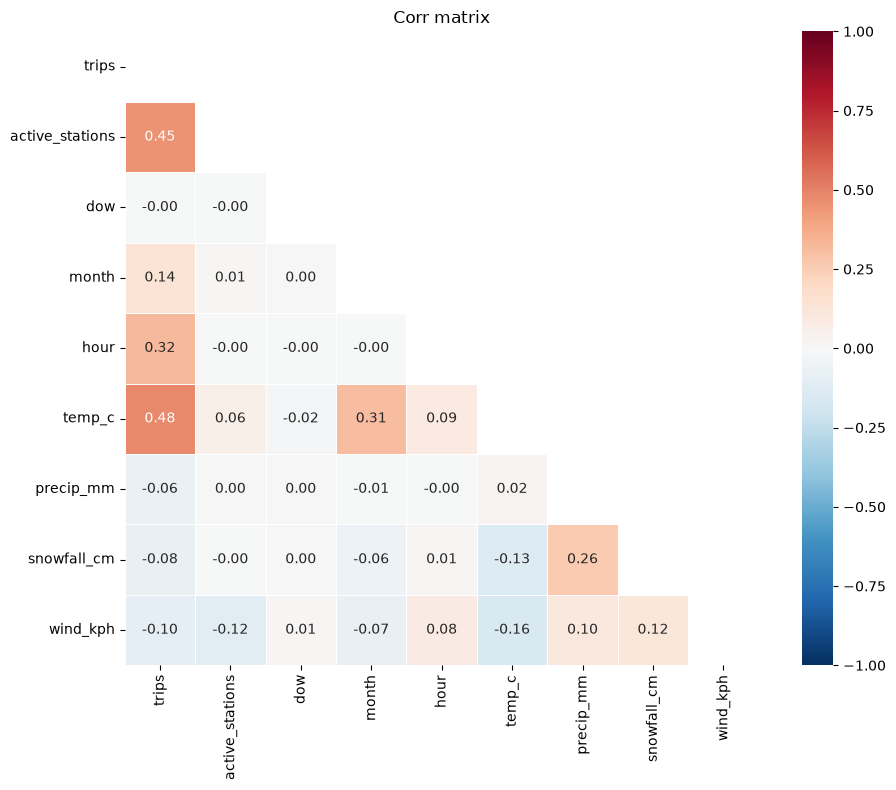

In [123]:
plt.figure(figsize = (10,8))
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f",
            cmap="RdBu_r", vmin=-1, vmax=1, center=0,
            square=True, linewidths=0.5)
plt.title('Corr matrix')
plt.tight_layout()
plt.show()


In [24]:
import statsmodels.api as sm

X = sm.add_constant(panel['delta_stations'])
y = panel['delta_trips']



In [25]:
model = sm.OLS(y, X).fit()

In [26]:
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:            delta_trips   R-squared:                       0.070
Model:                            OLS   Adj. R-squared:                  0.063
Method:                 Least Squares   F-statistic:                     10.10
Date:                Sun, 15 Nov 2026   Prob (F-statistic):            0.00184
Time:                        19:10:09   Log-Likelihood:                -1748.4
No. Observations:                 136   AIC:                             3501.
Df Residuals:                     134   BIC:                             3507.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                     coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------
const            2.35e+04   1.08e+04      2.

In [27]:
model_cl = sm.OLS(y, X).fit(cov_type='cluster', cov_kwds={'groups': panel['start_ward']})
print(model_cl.summary())

                            OLS Regression Results                            
Dep. Variable:            delta_trips   R-squared:                       0.070
Model:                            OLS   Adj. R-squared:                  0.063
Method:                 Least Squares   F-statistic:                     1.798
Date:                Sun, 15 Nov 2026   Prob (F-statistic):              0.194
Time:                        19:10:14   Log-Likelihood:                -1748.4
No. Observations:                 136   AIC:                             3501.
Df Residuals:                     134   BIC:                             3507.
Df Model:                           1                                         
Covariance Type:              cluster                                         
                     coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------
const            2.35e+04   1.45e+04      1.